# 05 실습 · 여행 상담 RAG에 사람 승인 붙이기

**바람길여행 상담 챗봇**이 고객 질문에 답변 초안을 만들면, **상담원이 확인한 뒤에만** 고객에게 발송한다.

번역 파이프라인(번역 → 검수 → 정리)처럼 단계를 노드로 나누고, 여기에 실무 필수 요소를 붙인다.

| 요소 | 이 실습에서 하는 일 |
|---|---|
| 체크포인터 | 멈춘 상태와 단계별 결과를 저장한다 |
| `thread_id` | 고객(상담 건)마다 대화를 따로 관리한다 |
| `interrupt` | 발송 직전에 멈추고 상담원에게 초안을 보여 준다 |
| `Command(resume=...)` | 상담원의 결정(승인·수정·재검색)을 넣고 이어서 실행한다 |

**그래프 흐름**

    START → retrieve → draft → review (멈춤) ─ 승인·수정 → send → END
                                    └─ 재검색 ─→ retrieve

- 자료: `travel_docs.csv` (가상의 은하군 여행 정보 22건)
- 복습: `감기환자 진료 데이터.csv` (맨 아래 복습 미션)

## 1. 준비

In [1]:
!pip install -q langgraph langchain langchain-openai langchain-community faiss-cpu pandas


[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os
os.environ["OPENAI_API_KEY"] = "sk-..."   # 본인 키

## 2. CSV → Document

CSV 한 줄(여행 정보 하나)을 Document 하나로 만든다.
- `page_content`: 제목 + 본문 (검색 대상)
- `metadata`: 문서 번호, 분류, 출처 (답변 근거 표시용)

한 줄이 300자 안팎으로 짧아서 따로 청킹하지 않는다.

In [4]:
import pandas as pd
from langchain_core.documents import Document

df = pd.read_csv("travel_docs.csv")
print(len(df), "건")
df.head(3)

22 건


,doc_id,category,source,title,body
0,T01,여행지 상세,은하군 관광 포털,솔바람섬 소개,솔바람섬은 은하군 노을항에서 배로 40분 거리에 있는 섬이다. 섬의 대표 명소는 별...
1,T02,여행지 상세,은하군 관광 포털,별빛전망대,별빛전망대는 솔바람섬 북쪽 언덕 꼭대기에 있는 천문 관측 명소이다. 맑은 날 밤에는...
2,T03,여행지 상세,은하군 관광 포털,청연계곡,청연계곡은 은하군 산골면에 있는 계곡으로 트레킹 코스가 유명하다. 계곡 입구에는 계...


In [5]:
docs = []
for _, row in df.iterrows():
    docs.append(Document(
        page_content=f"{row['title']}\n{row['body']}",
        metadata={"doc_id": row["doc_id"], "category": row["category"], "source": row["source"]},
    ))

print(docs[0].metadata)
print(docs[0].page_content)

{'doc_id': 'T01', 'category': '여행지 상세', 'source': '은하군 관광 포털'}
솔바람섬 소개
솔바람섬은 은하군 노을항에서 배로 40분 거리에 있는 섬이다. 섬의 대표 명소는 별빛전망대와 은빛해변이다. 섬 안의 대형 숙소로는 은빛해변 앞의 파도소리 리조트(인기 숙소)가 있다. 솔바람섬에 들어가는 방법은 솔바람페리 하나뿐이다. 여름 성수기에는 하루 방문객이 3천 명을 넘는다. 섬 둘레길은 천천히 걸으면 약 세 시간이 걸린다.


## 3. FAISS 벡터DB와 검색 확인

그래프를 만들기 전에 검색이 잘 되는지 먼저 확인한다. 점수는 **거리**라서 작을수록 질문과 비슷하다.

자료에는 이름이 비슷한 **혼동 주의 문서**(바람결여행, 솔바람호텔, 별빛캠핑장)가 섞여 있다. 검색이 이런 문서를 가져올 수 있어서, 사람이 확인하는 단계가 필요하다.

In [16]:
from langchain_community.vectorstores import FAISS
from langchain_openai import OpenAIEmbeddings

db = FAISS.from_documents(docs, OpenAIEmbeddings())

for d, score in db.similarity_search_with_score("바람길여행 취소하면 환불돼?", k=3):
    print(f"{score:.3f} | {d.metadata['doc_id']} | {d.page_content.splitlines()[0]}")

0.172 | T15 | 바람길여행 예약 취소·환불 규정
0.203 | T22 | [혼동 주의] 바람결여행 취소 규정
0.273 | T17 | 은하해운 결항·환불 규정


## 4. 그래프 만들기

| 노드 | 하는 일 |
|---|---|
| `retrieve` | 질문과 비슷한 문서 3개를 찾는다 |
| `draft` | 찾은 문서만 보고 답변 초안을 만든다 |
| `review` | **멈춘다.** 상담원이 승인 · 수정 · 재검색 중 하나를 고른다 |
| `send` | 고객에게 발송한다 (승인된 뒤에만 도달) |

`review`와 `send`를 나눈 이유: 재개하면 `review` 노드가 처음부터 다시 실행된다. 발송처럼 두 번 하면 안 되는 일은 `interrupt`가 있는 노드에 두지 않는다.

In [17]:
from typing import TypedDict, Literal
from langchain.chat_models import init_chat_model
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.types import interrupt, Command

llm = init_chat_model("openai:gpt-4o-mini", temperature=0)

PROMPT = """너는 바람길여행 상담원이다.
아래 문서에 있는 내용으로만 고객 질문에 답하고, 없으면 '확인 후 다시 안내드리겠습니다'라고 답해라.
답 끝에 근거 문서 번호를 [T01]처럼 적어라.

[문서]
{docs}"""

SENT = []   # 발송 기록 (실제로는 메일·카톡 발송)


class State(TypedDict):
    question: str   # 고객 질문
    docs: str       # 검색된 문서 (retrieve가 채움)
    draft: str      # 답변 초안 (draft가 채움)
    final: str      # 최종 발송 답변 (review가 채움)

In [18]:
# 노드 1: 검색
# 질문과 비슷한 문서 3개를 찾아 "[문서번호] 내용" 형태로 State에 저장
def retrieve(state):
    print(f"'{state['question']}' 질문에 맞는 여행 정보를 찾고 있습니다.")
    results = db.similarity_search(state["question"], k=3)
    docs = "\n\n".join(f"[{d.metadata['doc_id']}] {d.page_content}" for d in results)
    return {"docs": docs}


# 노드 2: 답변 초안
# 찾은 문서는 system에, 고객 질문은 user에 넣어 LLM이 초안을 쓴다
def draft(state):
    print("찾은 문서를 읽고 답변 초안을 쓰고 있습니다.")
    messages = [
        ("system", PROMPT.format(docs=state["docs"])),
        ("user", state["question"]),
    ]
    return {"draft": llm.invoke(messages).content}


# 노드 3: 상담원 확인 (interrupt)
# 초안과 근거 문서를 보여 주고 멈춘다. 재개되면 상담원의 결정에 따라 다음 노드를 정한다
#   {"type": "approve"}                  → 초안 그대로 발송
#   {"type": "edit", "answer": "..."}    → 고친 답변으로 발송
#   {"type": "research", "query": "..."} → 검색어를 바꿔 처음부터 다시
def review(state) -> Command[Literal["send", "retrieve"]]:
    print("발송 전에 상담원 확인을 기다립니다.")
    결정 = interrupt({"question": state["question"], "docs": state["docs"], "draft": state["draft"]})

    if 결정["type"] == "approve":
        return Command(goto="send", update={"final": state["draft"]})
    if 결정["type"] == "edit":
        return Command(goto="send", update={"final": 결정["answer"]})
    return Command(goto="retrieve", update={"question": 결정["query"]})


# 노드 4: 발송
# 승인된 경우에만 도달한다. 두 번 실행되면 안 되는 일이라 review와 분리했다
def send(state):
    SENT.append(state["final"])
    print("고객에게 답변을 발송했습니다.")
    return {}

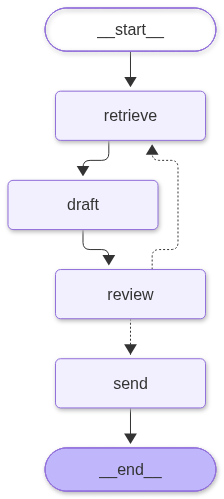

In [19]:
g = StateGraph(State)
g.add_node("retrieve", retrieve)
g.add_node("draft", draft)
g.add_node("review", review)
g.add_node("send", send)

g.add_edge(START, "retrieve")
g.add_edge("retrieve", "draft")
g.add_edge("draft", "review")      # review 다음은 Command가 정한다 (send 또는 retrieve)
g.add_edge("send", END)

memory = InMemorySaver()                     # 체크포인터: 멈춘 상태를 저장
app = g.compile(checkpointer=memory)
app

## 5. 상담 건 ① 승인하고 발송

상담 건마다 `thread_id`를 하나씩 쓴다. 실행하면 `review`에서 멈추고 `__interrupt__`에 상담원이 볼 내용이 담겨 온다.

In [20]:
cfg1 = {"configurable": {"thread_id": "상담-001"}}

r = app.invoke({"question": "별빛전망대는 무슨 요일에 쉬어요? 입장료도 알려주세요."}, cfg1)

화면 = r["__interrupt__"][0].value
print("\n[초안]\n" + 화면["draft"])

'별빛전망대는 무슨 요일에 쉬어요? 입장료도 알려주세요.' 질문에 맞는 여행 정보를 찾고 있습니다.
찾은 문서를 읽고 답변 초안을 쓰고 있습니다.
발송 전에 상담원 확인을 기다립니다.

[초안]
별빛전망대는 매주 월요일에 휴관하며, 입장료는 5천 원입니다. [T02]


멈춘 상태는 체크포인터에 저장되어 있어서 언제든 조회할 수 있다. 웹 화면이라면 이걸로 "승인 대기 목록"을 만든다.

In [21]:
st = app.get_state(cfg1)
print("다음 노드:", st.next)
print("대기 중인 질문:", st.interrupts[0].value["question"])
print("발송 기록:", SENT)          # 아직 비어 있음

다음 노드: ('review',)
대기 중인 질문: 별빛전망대는 무슨 요일에 쉬어요? 입장료도 알려주세요.
발송 기록: []


In [22]:
r = app.invoke(Command(resume={"type": "approve"}), cfg1)

print("\n[발송된 답변]\n" + r["final"])
print("발송 건수:", len(SENT))

발송 전에 상담원 확인을 기다립니다.
고객에게 답변을 발송했습니다.

[발송된 답변]
별빛전망대는 매주 월요일에 휴관하며, 입장료는 5천 원입니다. [T02]
발송 건수: 1


재개하면 "발송 전에 상담원 확인을 기다립니다."가 **한 번 더** 찍힌다. `review` 노드가 처음부터 다시 실행됐다는 증거다.
`send`를 따로 두었기 때문에 발송은 한 번만 일어난다.

## 6. 상담 건 ② 엉뚱한 문서 → 재검색 → 수정 발송

"바람길여행"과 "바람결여행"은 다른 회사다. 검색이 바람결여행 문서를 가져오면 초안이 틀린다.
상담원이 근거 문서를 보고 **검색어를 바꿔 재검색**시키고, 그래도 아쉬우면 **직접 고쳐서** 보낸다.

In [23]:
cfg2 = {"configurable": {"thread_id": "상담-002"}}

r = app.invoke({"question": "바람결 여행 상품 3일 전에 취소하면 환불돼요?"}, cfg2)

화면 = r["__interrupt__"][0].value
print("\n[근거 문서]\n" + 화면["docs"])
print("\n[초안]\n" + 화면["draft"])

'바람결 여행 상품 3일 전에 취소하면 환불돼요?' 질문에 맞는 여행 정보를 찾고 있습니다.
찾은 문서를 읽고 답변 초안을 쓰고 있습니다.
발송 전에 상담원 확인을 기다립니다.

[근거 문서]
[T15] 바람길여행 예약 취소·환불 규정
바람길여행 상품은 출발 10일 전까지 취소하면 전액 환불된다. 출발 5일에서 9일 전에 취소하면 80%, 2일에서 4일 전에 취소하면 30%를 환불하며, 출발 1일 전부터는 환불되지 않는다. 단, 숙소 비용은 해당 숙소 운영사의 취소 규정을 따른다. 환불은 결제 수단으로 영업일 기준 5일 안에 처리된다. 단체 예약은 별도 계약 조건을 따른다.

[T22] [혼동 주의] 바람결여행 취소 규정
바람결여행은 바람길여행과 이름이 비슷하지만 다른 여행사로, 본사는 청람시에 있다. 바람결여행 상품은 출발 3일 전까지 취소하면 전액 환불된다. 바람결여행은 은하군 지역 상품을 판매하지 않는다. 문의는 온라인 채팅으로만 받는다.

[T16] 해온호스피탈리티 숙소 취소 규정
이 규정은 해온호스피탈리티가 운영하는 파도소리 리조트와 노을스테이 호텔에 적용된다. 체크인 7일 전까지 취소하면 전액, 3일에서 6일 전에 취소하면 50%를 환불한다. 체크인 2일 전부터 당일까지는 환불되지 않는다. 천재지변으로 이용이 불가능한 경우에는 전액 환불한다. 환불 문의는 대표 전화로 받는다.

[초안]
바람결여행은 바람길여행과 다른 여행사로, 바람결여행 상품은 출발 3일 전까지 취소하면 전액 환불됩니다. 그러나 바람길여행의 규정에 대한 질문이라면, 바람길여행 상품은 출발 10일 전까지 취소하면 전액 환불됩니다. 확인 후 다시 안내드리겠습니다. [T22] [T15]


고객이 바람길여행 고객인지 확인했다고 하자. 검색어를 바꿔 다시 검색한다. 그래프는 `retrieve`로 돌아갔다가 다시 `review`에서 멈춘다.

In [24]:
r = app.invoke(Command(resume={"type": "research", "query": "바람길여행 출발 3일 전 취소 환불"}), cfg2)

print("\n[새 초안]\n" + r["__interrupt__"][0].value["draft"])

발송 전에 상담원 확인을 기다립니다.
'바람길여행 출발 3일 전 취소 환불' 질문에 맞는 여행 정보를 찾고 있습니다.
찾은 문서를 읽고 답변 초안을 쓰고 있습니다.
발송 전에 상담원 확인을 기다립니다.

[새 초안]
출발 3일 전 취소 시에는 30%의 환불이 가능합니다. 환불은 결제 수단으로 영업일 기준 5일 안에 처리됩니다. [T15]


초안에 숙소 환불 규정 안내를 덧붙이고 싶다면 직접 고쳐서 발송한다.

In [25]:
고친답변 = (
    "바람길여행 상품은 출발 2~4일 전에 취소하시면 30%가 환불됩니다. "
    "단, 숙소 비용은 숙소 운영사 규정을 따르니 함께 확인 부탁드립니다. [T15][T16]"
)
r = app.invoke(Command(resume={"type": "edit", "answer": 고친답변}), cfg2)

print("\n[발송된 답변]\n" + r["final"])
print("발송 건수:", len(SENT))

발송 전에 상담원 확인을 기다립니다.
고객에게 답변을 발송했습니다.

[발송된 답변]
바람길여행 상품은 출발 2~4일 전에 취소하시면 30%가 환불됩니다. 단, 숙소 비용은 숙소 운영사 규정을 따르니 함께 확인 부탁드립니다. [T15][T16]
발송 건수: 2


## 7. 체크포인터에 남은 기록 보기

- `memory.list(None)`: 저장된 상담 건(thread) 목록
- `get_state_history(cfg)`: 한 상담 건이 어떤 노드를 거쳐 왔는지 (최신 → 과거)

In [26]:
print("상담 건:", {c.config["configurable"]["thread_id"] for c in memory.list(None)})

상담 건: {'상담-002', '상담-001'}


In [27]:
for s in app.get_state_history(cfg2):
    print(s.next, "| 질문:", s.values.get("question", "")[:30])

() | 질문: 바람길여행 출발 3일 전 취소 환불
('send',) | 질문: 바람길여행 출발 3일 전 취소 환불
('review',) | 질문: 바람길여행 출발 3일 전 취소 환불
('draft',) | 질문: 바람길여행 출발 3일 전 취소 환불
('retrieve',) | 질문: 바람길여행 출발 3일 전 취소 환불
('review',) | 질문: 바람결 여행 상품 3일 전에 취소하면 환불돼요?
('draft',) | 질문: 바람결 여행 상품 3일 전에 취소하면 환불돼요?
('retrieve',) | 질문: 바람결 여행 상품 3일 전에 취소하면 환불돼요?
('__start__',) | 질문: 


`상담-002`는 검색 → 초안 → 확인을 **두 바퀴** 돌았다. 재검색 전후의 질문이 모두 기록에 남는다.

## 8. 실험: 체크포인터를 빼면?

멈추는 것까지는 된다. 하지만 **재개할 때** 멈춘 위치를 찾을 수 없어 에러가 난다.

In [28]:
app_no_memory = g.compile()                           # 체크포인터 없음
cfg3 = {"configurable": {"thread_id": "상담-003"}}

r = app_no_memory.invoke({"question": "솔바람페리는 하루 몇 번 다녀요?"}, cfg3)
print("멈춤:", "__interrupt__" in r)

try:
    app_no_memory.invoke(Command(resume={"type": "approve"}), cfg3)
except RuntimeError as e:
    print("재개 실패:", e)

'솔바람페리는 하루 몇 번 다녀요?' 질문에 맞는 여행 정보를 찾고 있습니다.
찾은 문서를 읽고 답변 초안을 쓰고 있습니다.
발송 전에 상담원 확인을 기다립니다.
멈춤: True
재개 실패: Cannot use Command(resume=...) without checkpointer


## 9. 정리

| 요소 | 핵심 |
|---|---|
| 체크포인터 | `compile(checkpointer=InMemorySaver())`. 없으면 재개가 안 된다 |
| `thread_id` | 상담 건마다 다르게. 같은 id면 이어서, 다르면 새로 |
| `interrupt(값)` | 노드 안에서 멈추고 값을 사람에게 보여 준다. 값은 dict·str처럼 저장 가능해야 한다 |
| `Command(resume=답)` | 답을 넣고 재개. 멈춘 노드는 **처음부터 다시** 실행된다 |
| `Command(goto=...)` | 사람의 결정에 따라 다음 노드를 고른다 |
| 노드 분리 | 발송·결제처럼 두 번 하면 안 되는 일은 `interrupt` 노드와 나눈다 |

---
# 복습 미션 · 감기환자 진료 데이터

`감기환자 진료 데이터.csv`로 같은 구조를 직접 만든다.

**상황**: 의사가 "비슷한 과거 진료 기록"을 참고해 소견 초안을 받고, **의사가 확인한 뒤에만** 진료 기록에 저장한다.

    START → retrieve → draft → review (멈춤) ─ 승인·수정 → save → END
                                    └─ 재검색 ─→ retrieve

| 미션 | 할 일 |
|---|---|
| M1 | CSV 한 줄 → Document (`page_content`는 `진료내용`, `metadata`는 환자ID·진단명·처방) |
| M2 | FAISS를 만들고 `"39도 고열에 기침"`으로 검색해 본다 |
| M3 | 4개 노드와 그래프를 만든다 (`send` 대신 `save`) |
| M4 | 환자 2명을 서로 다른 `thread_id`로 실행해 승인 · 재검색 · 수정을 해 본다 |
| M5 | `get_state_history`로 두 번째 환자가 거친 단계를 확인한다 |

> 실제 의료 서비스에서는 AI 초안이 그대로 기록되면 안 된다. 의사 승인 단계가 왜 필수인지 생각하며 만든다.

### M1 · CSV → Document

In [36]:
import pandas as pd
from langchain_core.documents import Document

df2 = pd.read_csv("감기환자_진료데이터.csv")

records = []
for _, row in df2.iterrows():
    # TODO: Document를 만들어 records에 추가
    pass

print(len(records), "건")
print(len(df2))
print(df2.columns)
print(df2.head())

0 건
30
Index(['환자ID', '진료일자', '이름', '나이', '성별', '증상', '체온', '증상지속일', '진단명', '처방',
       '진료구분', '진료내용'],
      dtype='str')
   환자ID        진료일자   이름  나이 성별          증상    체온  증상지속일      진단명     처방 진료구분  \
0  P001  2025-07-02  김**  19  남  두통/인후통/재채기  36.7      5  급성 비인두염  수액 처방   초진   
1  P002  2025-08-19  이**  16  남         피로감  38.0      2  급성 기관지염  진해거담제   재진   
2  P003  2025-02-12  박**   5  남  코막힘/근육통/두통  36.8      4   상기도 감염    해열제   초진   
3  P004  2025-11-20  최**  38  남   오한/피로감/기침  39.1      7    독감 의심    해열제   재진   
4  P005  2025-02-13  정**  29  남          가래  37.0      7   상기도 감염    해열제   초진   

                                                진료내용  
0  19세 남성 환자로 5일 전부터 두통, 인후통, 재채기 증상 호소. 체온 36.7도...  
1  2일 전부터 시작된 피로감(으)로 내원. 내원 시 체온 38.0도로 측정됨. 진찰 ...  
2  4일 전부터 시작된 코막힘, 근육통, 두통(으)로 내원. 체온 36.8도로 미열은 ...  
3  7일 전부터 시작된 오한, 피로감, 기침(으)로 내원. 내원 시 체온 39.1도로 ...  
4  7일 전부터 시작된 가래(으)로 내원. 체온 37.0도로 미열은 없음. 진찰 결과 ...  


### M2 · FAISS와 검색

In [31]:
# TODO: db2 = FAISS.from_documents(...)
# TODO: "39도 고열에 기침"으로 similarity_search_with_score 해 보기

### M3 · 그래프

- State: `question`, `docs`, `draft`, `final`
- `review`의 resume 형식은 여행 실습과 같게: `approve` / `edit` / `research`
- 프롬프트 예: "너는 진료 보조 AI다. 아래 과거 진료 기록만 참고해 예상 진단과 처방을 제안하고, 근거 환자ID를 적어라."

In [33]:
# TODO: State, retrieve, draft, review, save 정의
# TODO: 그래프 조립 + InMemorySaver로 compile

### M4 · 환자 2명 실행

In [34]:
# TODO: 환자-A: "38세 남성, 7일째 오한과 기침, 체온 39.1도" → 승인
# TODO: 환자-B: "6세 여아, 재채기와 가래" → 재검색 후 수정 저장

### M5 · 기록 확인

In [35]:
# TODO: memory.list(None)로 thread 목록, get_state_history로 환자-B 단계 확인

---
### 예시 답안 (막힐 때만 펼쳐 보기)

In [ ]:
# M1
records = []
for _, row in df2.iterrows():
    records.append(Document(
        page_content=row["진료내용"],
        metadata={"환자ID": row["환자ID"], "진단명": row["진단명"], "처방": row["처방"]},
    ))

# M2
db2 = FAISS.from_documents(records, OpenAIEmbeddings())
for d, score in db2.similarity_search_with_score("39도 고열에 기침", k=3):
    print(f"{score:.3f} | {d.metadata['환자ID']} | {d.metadata['진단명']} | {d.page_content[:40]}")

In [ ]:
# M3
PROMPT2 = """너는 진료 보조 AI다.
아래 과거 진료 기록만 참고해 예상 진단과 처방을 제안하고, 근거 환자ID를 [P001]처럼 적어라.
최종 판단은 의사가 한다는 문장을 마지막에 붙여라.

[과거 진료 기록]
{docs}"""

SAVED = []   # 진료 기록 저장소


class State2(TypedDict):
    question: str
    docs: str
    draft: str
    final: str


# 노드 1: 비슷한 과거 진료 기록 3건 검색
def retrieve2(state):
    print(f"'{state['question']}'와 비슷한 과거 진료 기록을 찾고 있습니다.")
    results = db2.similarity_search(state["question"], k=3)
    docs = "\n".join(f"[{d.metadata['환자ID']}] {d.page_content}" for d in results)
    return {"docs": docs}


# 노드 2: 과거 기록만 보고 소견 초안 작성
def draft2(state):
    print("과거 기록을 읽고 소견 초안을 쓰고 있습니다.")
    messages = [("system", PROMPT2.format(docs=state["docs"])), ("user", state["question"])]
    return {"draft": llm.invoke(messages).content}


# 노드 3: 의사 확인 (interrupt) → 승인 · 수정 · 재검색
def review2(state) -> Command[Literal["save", "retrieve"]]:
    print("저장 전에 의사 확인을 기다립니다.")
    결정 = interrupt({"question": state["question"], "docs": state["docs"], "draft": state["draft"]})
    if 결정["type"] == "approve":
        return Command(goto="save", update={"final": state["draft"]})
    if 결정["type"] == "edit":
        return Command(goto="save", update={"final": 결정["answer"]})
    return Command(goto="retrieve", update={"question": 결정["query"]})


# 노드 4: 승인된 소견만 진료 기록에 저장
def save(state):
    SAVED.append(state["final"])
    print("진료 기록에 저장했습니다.")
    return {}


g2 = StateGraph(State2)
g2.add_node("retrieve", retrieve2)
g2.add_node("draft", draft2)
g2.add_node("review", review2)
g2.add_node("save", save)
g2.add_edge(START, "retrieve")
g2.add_edge("retrieve", "draft")
g2.add_edge("draft", "review")
g2.add_edge("save", END)

memory2 = InMemorySaver()
app2 = g2.compile(checkpointer=memory2)
app2

In [ ]:
# M4 - 환자-A: 승인
cfgA = {"configurable": {"thread_id": "환자-A"}}
r = app2.invoke({"question": "38세 남성, 7일째 오한과 기침, 체온 39.1도"}, cfgA)
print("\n[초안]\n" + r["__interrupt__"][0].value["draft"])

r = app2.invoke(Command(resume={"type": "approve"}), cfgA)
print("저장 건수:", len(SAVED))

In [ ]:
# M4 - 환자-B: 재검색 → 수정 저장
cfgB = {"configurable": {"thread_id": "환자-B"}}
r = app2.invoke({"question": "6세 여아, 재채기와 가래"}, cfgB)
print("\n[근거]\n" + r["__interrupt__"][0].value["docs"])

r = app2.invoke(Command(resume={"type": "research", "query": "소아 재채기 기침 가래 37.9도"}), cfgB)
print("\n[새 초안]\n" + r["__interrupt__"][0].value["draft"])

r = app2.invoke(Command(resume={"type": "edit", "answer": "급성 기관지염 의심. 항히스타민제 처방, 3일 후 재진. [P027]"}), cfgB)
print("\n[저장된 소견]\n" + r["final"])
print("저장 건수:", len(SAVED))

In [ ]:
# M5
print("환자:", {c.config["configurable"]["thread_id"] for c in memory2.list(None)})
for s in app2.get_state_history(cfgB):
    print(s.next, "| 질문:", s.values.get("question", "")[:30])